# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Grupo X · **Tema:** Atividades complementares e extensão

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [2]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [3]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [4]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Grupo X | Tema: Atividades complementares e extensão


,intenção,descrição
0,computo_horas,Contabilização de horas de extensão e de complementares
1,tipos_atividades,Tipos de atividades de extensão e de complementares
2,curricularizacao_extensao,Informações e definições sobre a curricularização de atividades de extensão ...
3,organizacao_ufms,Organização da UFMS
4,atividades_remuneradas,Atividades remuneradas


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [5]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: ['3 texto(s) duplicado(s) dentro do arquivo']
Problemas no teste:  ['4 texto(s) duplicado(s) dentro do arquivo']
Vazamento treino→teste: ['Vlw', 'Salve', 'tmj', 'obrigado', 'Bom dia', 'Boa tarde', 'Boa noite', 'Valeu', 'Obrigado', 'Agradeço', 'Falou', 'Até mais']


origem,humano,llm,total
intencao,,,
atividades_remuneradas,8,4,12
chitchat,44,0,44
computo_horas,47,0,47
curricularizacao_extensao,10,3,13
fora_dominio,27,1,28
organizacao_ufms,21,0,21
tipos_atividades,40,0,40
total,197,8,205


origem,coletado,total
intencao,,
atividades_remuneradas,6,6
chitchat,71,71
computo_horas,19,19
curricularizacao_extensao,6,6
fora_dominio,44,44
organizacao_ufms,20,20
tipos_atividades,19,19
total,185,185


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [ ]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [ ]:
# 🔨 TODO

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [6]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    # 🔨 TODO: outras variações (ex.: com stopwords, só unigramas, embeddings...)
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Naive Bayes": lambda: MultinomialNB(alpha=1.0),
    "SVM": lambda: LinearSVC(C=1.0, random_state=RANDOM_STATE ),
}

def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Árvore de decisão,0.770,0.053,0.883,1.000
1,TF-IDF caracteres,SVM,0.757,0.044,0.873,1.000
2,TF-IDF caracteres,Regressão logística,0.725,0.069,0.859,1.000
3,TF-IDF palavras,Rede neural (MLP),0.705,0.091,0.859,1.000
4,TF-IDF caracteres,Random Forest,0.676,0.058,0.868,1.000
5,TF-IDF caracteres,Rede neural (MLP),0.651,0.070,0.795,1.000
6,TF-IDF palavras,Random Forest,0.570,0.033,0.824,1.000
7,TF-IDF palavras,Árvore de decisão,0.560,0.035,0.771,1.000
8,TF-IDF palavras,SVM,0.464,0.053,0.717,1.000
9,TF-IDF palavras,Regressão logística,0.412,0.064,0.702,1.000


Ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [13]:
busca_regressao = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_regressao.fit(treino["texto"], treino["escopo"])
clf_regressao = busca_regressao.best_estimator_
#print(busca_regressao.best_params_, round(busca_regressao.best_score_, 3))

busca_arvore = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__max_depth": [None, 5, 10, 20, 30],
        "classificador__min_samples_split": [2, 5, 10],
        "classificador__min_samples_leaf": [1, 2, 4]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_arvore.fit(treino["texto"], treino["escopo"])
#print(busca_arvore.best_params_, round(busca_arvore.best_score_, 3))

busca_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MLPClassifier(max_iter=500, random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__hidden_layer_sizes": [(16,), (32,)],
        "classificador__alpha": [0.0001, 0.001, 0.01]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_mlp.fit(treino["texto"], treino["escopo"])
#print(busca_mlp.best_params_, round(busca_mlp.best_score_, 3))

busca_floresta_aleatoria = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))]),
    param_grid={
        "classificador__n_estimators": [10, 20, 50],
        "classificador__max_depth": [None, 10, 20]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_floresta_aleatoria.fit(treino["texto"], treino["escopo"])
#print(busca_floresta_aleatoria.best_params_, round(busca_floresta_aleatoria.best_score_, 3))

busca_bayes = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MultinomialNB())]),
    param_grid={
        "classificador__alpha": [0.01, 0.1, 1.0, 10.0]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_bayes.fit(treino["texto"], treino["escopo"])
#print(busca_bayes.best_params_, round(busca_bayes.best_score_, 3))

busca_svm = GridSearchCV(
    Pipeline([ ("vetorizador", tfidf_caracteres()),("classificador", LinearSVC(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_svm.fit(treino["texto"], treino["escopo"])
#print(busca_svm.best_params_, round(busca_svm.best_score_, 3))

resultados = []

buscas = {
    "Regressão Logística": busca_regressao,
    "Árvore de Decisão": busca_arvore,
    "MLP": busca_mlp,
    "Random Forest": busca_floresta_aleatoria,
    "Naive Bayes": busca_bayes,
    "SVM": busca_svm
}

for nome, busca in buscas.items():
    resultados.append({
        "Algoritmo": nome,
        "Melhores parâmetros": busca.best_params_,
        "F1 macro": busca.best_score_
    })

tab_resultados = pd.DataFrame(resultados)

tab_resultados = tab_resultados.sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)

display(tab_resultados.round(3))

,Algoritmo,Melhores parâmetros,F1 macro
0,Árvore de Decisão,"{'classificador__max_depth': None, 'classificador__min_samples_leaf': 4, 'cl...",0.792
1,SVM,{'classificador__C': 10},0.777
2,Regressão Logística,{'classificador__C': 100},0.759
3,Random Forest,"{'classificador__max_depth': 10, 'classificador__n_estimators': 50}",0.693
4,MLP,"{'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (32,)}",0.670
5,Naive Bayes,{'classificador__alpha': 0.01},0.621


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

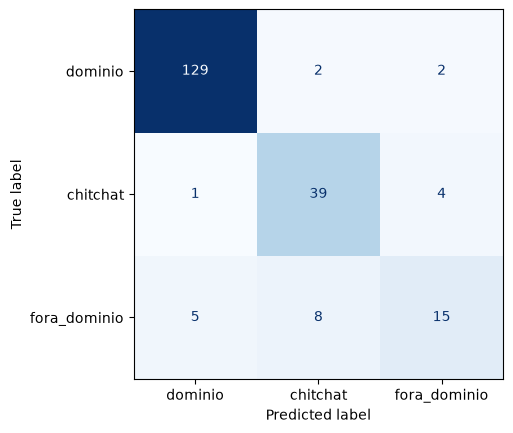

Taxa de falso positivo: 0.083
Taxa de falso negativo: 0.03


In [16]:
melhor_classificador = max(buscas, key=lambda nome: buscas[nome].best_score_)
clf_escopo = buscas[melhor_classificador].best_estimator_

prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

real = treino["escopo"].to_numpy()

falso_positivo = ((real != "dominio") & (prev_cv == "dominio")).sum()
falso_negativo = ((real == "dominio") & (prev_cv != "dominio")).sum()

total_negativas = (real != "dominio").sum()
total_dominio = (real == "dominio").sum()

print("Taxa de falso positivo:", round(falso_positivo / total_negativas, 3))
print("Taxa de falso negativo:", round(falso_negativo / total_dominio, 3))

---
## 5. Classificador de tema (intenções do domínio)


In [18]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.548,0.120,0.646,1.000
1,TF-IDF caracteres,Rede neural (MLP),0.521,0.057,0.593,1.000
2,TF-IDF palavras,Rede neural (MLP),0.520,0.099,0.661,1.000
3,TF-IDF caracteres,SVM,0.519,0.093,0.601,1.000
4,TF-IDF palavras,SVM,0.494,0.073,0.661,1.000
5,TF-IDF palavras,Regressão logística,0.477,0.061,0.654,1.000
6,TF-IDF caracteres,Random Forest,0.468,0.090,0.579,1.000
7,TF-IDF palavras,Random Forest,0.457,0.104,0.547,1.000
8,TF-IDF palavras,Árvore de decisão,0.320,0.099,0.360,1.000
9,TF-IDF caracteres,Árvore de decisão,0.306,0.100,0.376,1.000


In [21]:
busca_regressao_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_regressao_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_regressao_tema.best_estimator_
#print(busca_regressao_tema.best_params_, round(busca_regressao_tema.best_score_, 3))

busca_arvore_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__max_depth": [None, 5, 10, 20, 30],
        "classificador__min_samples_split": [2, 5, 10],
        "classificador__min_samples_leaf": [1, 2, 4]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_arvore_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_arvore_tema.best_params_, round(busca_arvore_tema.best_score_, 3))

busca_mlp_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MLPClassifier(max_iter=500, random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__hidden_layer_sizes": [(16,), (32,)],
        "classificador__alpha": [0.0001, 0.001, 0.01]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_mlp_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_mlp_tema.best_params_, round(busca_mlp_tema.best_score_, 3))

busca_floresta_aleatoria_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))]),
    param_grid={
        "classificador__n_estimators": [10, 20, 50],
        "classificador__max_depth": [None, 10, 20]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_floresta_aleatoria_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_floresta_aleatoria_tema.best_params_, round(busca_floresta_aleatoria_tema.best_score_, 3))

busca_bayes_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MultinomialNB())]),
    param_grid={
        "classificador__alpha": [0.01, 0.1, 1.0, 10.0]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_bayes_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_bayes_tema.best_params_, round(busca_bayes_tema.best_score_, 3))

busca_svm_tema = GridSearchCV(
    Pipeline([ ("vetorizador", tfidf_caracteres()),("classificador", LinearSVC(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_svm_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_svm_tema.best_params_, round(busca_svm_tema.best_score_, 3))

resultados = []

buscas = {
    "Regressão Logística": busca_regressao,
    "Árvore de Decisão": busca_arvore_tema,
    "MLP": busca_mlp_tema,
    "Random Forest": busca_floresta_aleatoria_tema,
    "Naive Bayes": busca_bayes_tema,
    "SVM": busca_svm_tema
}

for nome, busca in buscas.items():
    resultados.append({
        "Algoritmo": nome,
        "Melhores parâmetros": busca.best_params_,
        "F1 macro": busca.best_score_
    })

tab_resultados = pd.DataFrame(resultados)

tab_resultados = tab_resultados.sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)

display(tab_resultados.round(3))

,Algoritmo,Melhores parâmetros,F1 macro
0,Regressão Logística,{'classificador__C': 100},0.759
1,SVM,{'classificador__C': 10},0.574
2,MLP,"{'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (16,)}",0.538
3,Naive Bayes,{'classificador__alpha': 0.01},0.533
4,Random Forest,"{'classificador__max_depth': 10, 'classificador__n_estimators': 50}",0.487
5,Árvore de Decisão,"{'classificador__max_depth': None, 'classificador__min_samples_leaf': 4, 'cl...",0.368


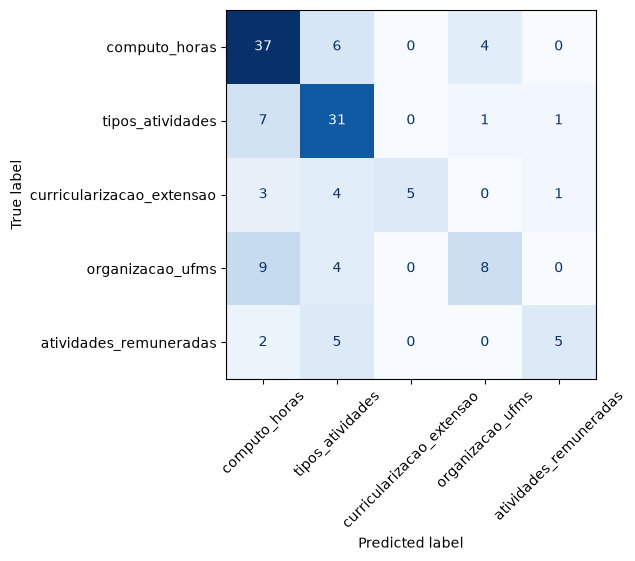

                           precision    recall  f1-score   support

   atividades_remuneradas       0.71      0.42      0.53        12
            computo_horas       0.64      0.79      0.70        47
curricularizacao_extensao       1.00      0.38      0.56        13
         organizacao_ufms       0.62      0.38      0.47        21
         tipos_atividades       0.62      0.78      0.69        40

                 accuracy                           0.65       133
                macro avg       0.72      0.55      0.59       133
             weighted avg       0.67      0.65      0.63       133

Taxa de falso positivo: 0.083
Taxa de falso negativo: 0.03


In [22]:
melhor_classificador = max(buscas, key=lambda nome: buscas[nome].best_score_)
clf_escopo = buscas[melhor_classificador].best_estimator_

prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

real = treino["escopo"].to_numpy()

falso_positivo = ((real != "dominio") & (prev_cv == "dominio")).sum()
falso_negativo = ((real == "dominio") & (prev_cv != "dominio")).sum()

total_negativas = (real != "dominio").sum()
total_dominio = (real == "dominio").sum()

print("Taxa de falso positivo:", round(falso_positivo / total_negativas, 3))
print("Taxa de falso negativo:", round(falso_negativo / total_dominio, 3))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [ ]:
# 🔨 TODO

---
## 7. Salvar os modelos finais

In [ ]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py